In [51]:
#declaring the necesary librarys
import numpy as np
import matplotlib.pyplot as plt

Part 1 of 4: we will study the motion of a small body under the gravitational attraction of a much more massive central body. We assume that the central body remains fixed at the origin (0, 0), and that the motion takes place in the XY plane.

We will first derive the equations of motion using Newton's second law, then express them in astronomical units (AU) and finally rewrite them as a system of four first-order differential equations suitable for numerical integration using the RK4 method.

In [52]:
#defining the equations of motions with a function 
def kepler_equations(t, state):

    #extracting position and velocity components
    x, y, vx, vy = state

    #distance from the central body
    r = np.sqrt(x**2 + y**2)

    #acceleration components
    ax = -4 * np.pi**2 * x / r**3
    ay = -4 * np.pi**2 * y / r**3

    #returning the derivatives
    return np.array([vx, vy, ax, ay])

Part 2 of 4: We will study bounded elliptical orbits by numerically integrating the equations of motion using the RK4 method.

The shape of the orbit depends on the specific orbital energy, which is given by:

$$
\epsilon=\frac{1}{2}v^2-\frac{4\pi^2}{r}
$$

For a bounded orbit, the specific energy must be negative ($\epsilon<0$). We will choose suitable initial conditions, integrate the equations of motion and plot the resulting trajectory in the XY plane.

In [53]:
#defining Fourth-order Runge-Kutta method as a function
def rk4(f, X0, tlist):

    #initial time, final time and step size
    t0, tf, dt = tlist

    #creating the time array
    n = int(np.ceil((tf - t0) / dt))
    t = np.linspace(t0, tf, n + 1)

    #initialize the solution array
    X = np.zeros((n + 1, len(X0)))
    X[0] = X0

    #RK4 integration through a loop to set the values and formula
    for i in range(n):

        h = t[i + 1] - t[i]

        k1 = f(t[i], X[i])
        k2 = f(t[i] + h/2, X[i] + h*k1/2)
        k3 = f(t[i] + h/2, X[i] + h*k2/2)
        k4 = f(t[i] + h, X[i] + h*k3)

        X[i + 1] = X[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return t, X

2(a) Initial conditions

We consider an initial position of $r_0=(1,0)$ AU and an initial velocity of $v_0=(0,v_{y,0})$ AU/year, as specified in the assignment.

To obtain an elliptical orbit, we must choose an initial velocity such that the specific orbital energy is negative:

$$
\epsilon_0=\frac{1}{2}v_{y,0}^2-4\pi^2<0
$$

We choose an initial velocity of $v_{y,0}=5$ AU/year. Therefore, the initial specific energy is:

$$
\epsilon_0=\frac{1}{2}(5)^2-4\pi^2
$$

$$
\epsilon_0\approx -26.9784
$$

Since the specific energy is negative, the resulting orbit is bounded and therefore elliptical.

In [54]:
#initial position and velocity
X0 = [1.0, 0.0, 0.0, 5.0]

#obtaining the initial specific orbital energy
x0, y0, vx0, vy0 = X0

r0 = np.sqrt(x0**2 + y0**2)
v0 = np.sqrt(vx0**2 + vy0**2)

epsilon0 = 0.5 * v0**2 - (4 * np.pi**2 / r0)

#verifying the result
print("Initial specific orbital energy:", epsilon0)

Initial specific orbital energy: -26.978417604357432


In [55]:
#time interval and step size
tlist = [0, 1, 0.001]

#numerical integration using RK4 function
t, X = rk4(kepler_equations, X0, tlist)

#extract position coordinates in the 2 dimensions we're working on
x = X[:, 0]
y = X[:, 1]

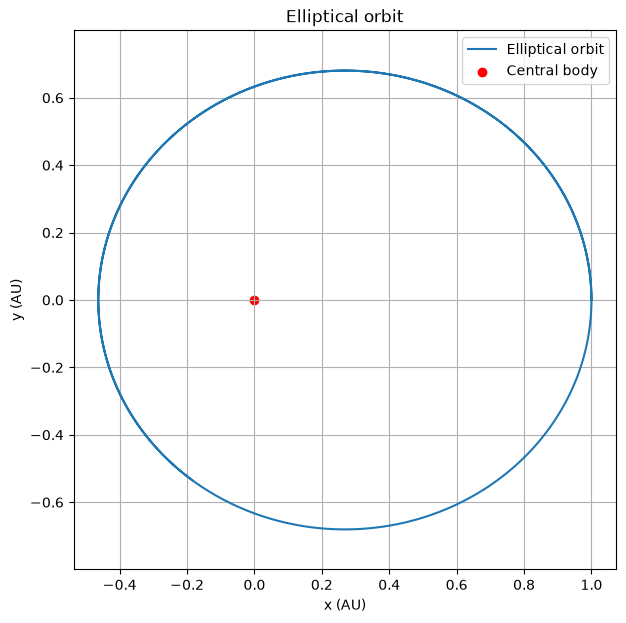

In [56]:
#plot the elliptical orbit results
plt.figure(figsize=(7, 7))

plt.plot(x, y, label='Elliptical orbit')
plt.scatter(0, 0, color='red', label='Central body')

plt.xlabel('x (AU)')
plt.ylabel('y (AU)')
plt.title('Elliptical orbit')
plt.axis('equal')
plt.grid()
plt.legend()

plt.show()

COMMENTS:  The numerical simulation produces a closed elliptical trajectory, as expected for a negative specific orbital energy. The central body is located at one of the two foci of the ellipse rather than at its geometric centre. This is consistent with Kepler's First Law. The initial energy value of approximately $-26.9784$ confirms that the orbit is bounded.

2(b) Conservation of specific orbital energy

The specific orbital energy is a conserved quantity throughout the motion. Therefore, its value should remain constant during the numerical integration.

To check the numerical stability of our simulation, we calculate the specific energy at every time step using the position and velocity obtained from the RK4 method.

The specific orbital energy is given by:

$$
\epsilon(t)=\frac{1}{2}(v_x^2+v_y^2)-\frac{4\pi^2}{r(t)}
$$

We then plot its evolution over time and compare it with the initial energy value. Any deviations from this value are caused by numerical integration errors.

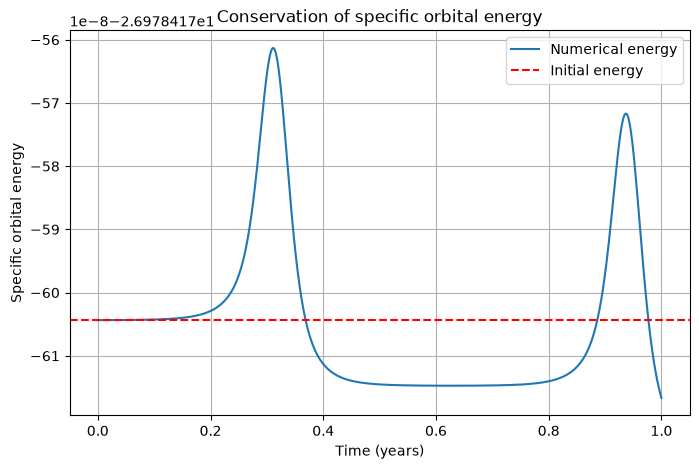

Maximum absolute energy deviation: 4.3051826992268616e-08


In [57]:
#extracting velocity components
vx = X[:, 2]
vy = X[:, 3]

#using the formula for distance from the central body
r = np.sqrt(x**2 + y**2)

#calculating the specific orbital energy at each time step
epsilon = 0.5 * (vx**2 + vy**2) - (4 * np.pi**2 / r)

#plotting the specific orbital energy over time
plt.figure(figsize=(8, 5))

plt.plot(t, epsilon, label='Numerical energy')
plt.axhline(epsilon0, color='red', linestyle='--',
            label='Initial energy')

plt.xlabel('Time (years)')
plt.ylabel('Specific orbital energy')
plt.title('Conservation of specific orbital energy')
plt.grid()
plt.legend()

plt.show()

#obtaining the maximum absolute energy deviation
max_error = np.max(np.abs(epsilon - epsilon0))

#results
print("Maximum absolute energy deviation:", max_error)

COMMENTS: The numerical energy remains very close to its initial value throughout the simulation, confirming that the specific orbital energy is well conserved. Small oscillations can be observed in the numerical energy, which are caused by the numerical errors introduced by the RK4 integration method. However, these deviations are extremely small. The maximum absolute energy deviation is approximately $4.31\times10^{-8}$, which is negligible compared to the initial energy value. Therefore, the chosen time step ($dt=0.001$) provides sufficient numerical accuracy for this simulation, and no further reduction is necessary.

2(c) Verification of Kepler's Second Law

Kepler's Second Law states that the line joining a planet and the Sun sweeps out equal areas in equal intervals of time.

Mathematically, this can be expressed as:

$$
r^2(t)\dot{\theta}(t)=\text{constant}
$$

To verify this law numerically, we first calculate the polar coordinates from the Cartesian coordinates obtained in the previous simulation:

$$
r(t)=\sqrt{x(t)^2+y(t)^2}
$$

$$
\theta(t)=\operatorname{atan2}(y(t),x(t))
$$

We use the NumPy function `np.unwrap()` to avoid discontinuities in the angular coordinate.

In [58]:
#obtaining the polar coordinates
r = np.sqrt(x**2 + y**2)

theta = np.unwrap(np.arctan2(y, x))

In [59]:
#numerical derivative using the central difference method as a function
def numerical_derivative(values, t):

    derivative = np.zeros_like(values)

    #central difference for interior points
    derivative[1:-1] = (
        values[2:] - values[:-2]
    ) / (t[2:] - t[:-2])

    #second-order forward difference at the first point
    h = t[1] - t[0]
    derivative[0] = (
        -3*values[0] + 4*values[1] - values[2]
    ) / (2*h)

    #second-order backward difference at the last point
    h = t[-1] - t[-2]
    derivative[-1] = (
        3*values[-1] - 4*values[-2] + values[-3]
    ) / (2*h)

    return derivative


#calculating the angular velocity
theta_dot = numerical_derivative(theta, t)

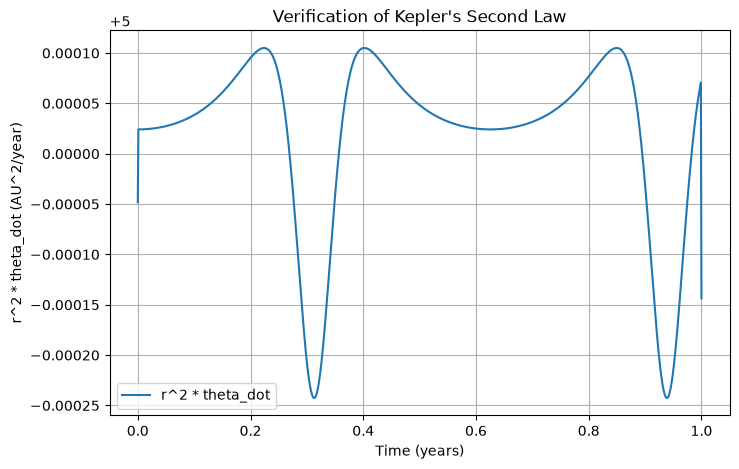

Mean value: 5.000020607613946
Standard deviation: 8.566759800366557e-05
Maximum deviation from theoretical value: 0.00024258224382300853


In [60]:
#r^2 * theta_dot formula
angular_momentum = r**2 * theta_dot

#plotting the result over time
plt.figure(figsize=(8, 5))

plt.plot(t, angular_momentum, label='r^2 * theta_dot')

plt.xlabel('Time (years)')
plt.ylabel('r^2 * theta_dot (AU^2/year)')
plt.title("Verification of Kepler's Second Law")
plt.grid()
plt.legend()

plt.show()

#numerical statistics using numpy statistic methods
print("Mean value:", np.mean(angular_momentum))
print("Standard deviation:", np.std(angular_momentum))
print("Maximum deviation from theoretical value:",
      np.max(np.abs(angular_momentum - 5.0)))

COMMENTS: The numerical results show that $r^2\dot{\theta}$ remains approximately constant throughout the simulation, with a mean value of $5.000021$ AU²/year, which is very close to the theoretical value of $5$ AU²/year. Small oscillations can be observed due to the numerical approximation used to calculate the angular derivative. However, the maximum deviation from the theoretical value is only approximately $2.43\times10^{-4}$. These results confirm that the angular momentum per unit mass is conserved and therefore verify Kepler's Second Law: equal areas are swept out in equal intervals of time.

Part 3 of 4: We study unbounded trajectories under the gravitational attraction of the central body.

The shape of the orbit depends on the specific orbital energy:

$$
\epsilon=\frac{1}{2}v^2-\frac{4\pi^2}{r}
$$

When $\epsilon>0$, the trajectory is hyperbolic, whereas when $\epsilon=0$, the trajectory is parabolic.

We will choose initial conditions with positive specific energy and use the RK4 method to simulate the motion.

The trajectory should show the body approaching the central mass, passing through its point of closest approach (periapsis), and then moving away again along the same hyperbolic branch.

We choose the following initial conditions:

$$
(x_0,y_0)=(-5,1)
$$

$$
(v_{x,0},v_{y,0})=(5,0)
$$

The body initially moves towards the central mass, located at the origin.

The initial distance is:

$$
r_0=\sqrt{(-5)^2+1^2}=\sqrt{26}
$$

Therefore, the initial specific energy is:

$$
\epsilon_0=\frac{1}{2}(5)^2-\frac{4\pi^2}{\sqrt{26}}
$$

$$
\epsilon_0\approx4.757645
$$

Since the specific energy is positive, the resulting trajectory is expected to be hyperbolic.

In [61]:
#initial conditions for the hyperbolic orbit
X0_3 = [-5.0, 1.0, 5.0, 0.0]

#obtaining the initial specific energy
x0_3, y0_3, vx0_3, vy0_3 = X0_3

r0_3 = np.sqrt(x0_3**2 + y0_3**2)
v0_3 = np.sqrt(vx0_3**2 + vy0_3**2)

epsilon0_3 = 0.5 * v0_3**2 - (4 * np.pi**2 / r0_3)

#checking the result
print("Initial specific orbital energy:", epsilon0_3)

Initial specific orbital energy: 4.757645318062174


In [62]:
#time interval and step size
tlist_3 = [0, 2, 0.001]

#numerical integration using RK4 function
t3, X3 = rk4(kepler_equations, X0_3, tlist_3)

#obtaining position coordinates
x3 = X3[:, 0]
y3 = X3[:, 1]

#calculating the distance from the central body
r3 = np.sqrt(x3**2 + y3**2)

#point of closest approach
i_peri = np.argmin(r3)

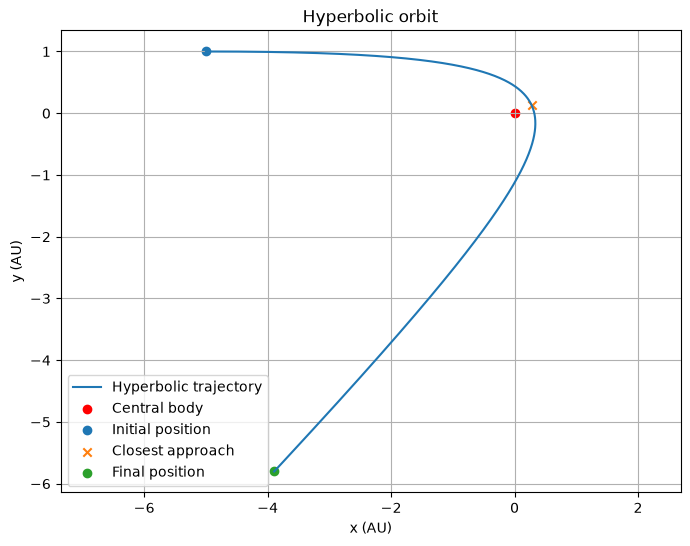

Closest approach distance: 0.3054126695742265 AU
Time of closest approach: 0.798 years


In [63]:
#plotting the hyperbolic trajectory
plt.figure(figsize=(8, 6))

plt.plot(x3, y3, label='Hyperbolic trajectory')

plt.scatter(0, 0, color='red', label='Central body')
plt.scatter(x3[0], y3[0], label='Initial position')
plt.scatter(x3[i_peri], y3[i_peri], marker='x',
            label='Closest approach')
plt.scatter(x3[-1], y3[-1], label='Final position')

plt.xlabel('x (AU)')
plt.ylabel('y (AU)')
plt.title('Hyperbolic orbit')
plt.axis('equal')
plt.grid()
plt.legend()

plt.show()

#distance from the cebtral body at the reach momment
print("Closest approach distance:", r3[i_peri], "AU")
print("Time of closest approach:", t3[i_peri], "years")

COMMENTS: The numerical simulation produces an open hyperbolic trajectory, as expected from the positive initial specific orbital energy ($\epsilon_0\approx 4.757645$). The trajectory shows the body approaching the central mass, passing through its point of closest approach (periapsis), and subsequently moving away from it. The simulation represents a single continuous hyperbolic branch, in agreement with the clarification provided by the professor. This result illustrates Kepler's First Law, which states that gravitational orbits are conic sections, including ellipses, parabolas and hyperbolas.

Part 4 of 4: Circular orbits and Kepler's Third Law

In this final part, we return to elliptical orbits and focus on the particular case of circular motion. We will study how the orbital period depends on the radius of the orbit and investigate Kepler's Third Law.

We will first derive analytically the initial velocity required to obtain a circular orbit. Then, using the RK4 method, we will simulate circular orbits with different initial radii and calculate their corresponding orbital periods.

Finally, we will represent the relationship between the orbital period and the orbital radius using a log-log plot and determine the corresponding power-law exponent through a linear fit. This will allow us to verify Kepler's Third Law numerically.

4(a) Circular orbit velocity

For an orbit to be perfectly circular, the gravitational acceleration must provide the centripetal acceleration required to maintain circular motion.

The centripetal acceleration is given by:

$$
a_c=\frac{v^2}{r}
$$

In our astronomical units, the gravitational acceleration has magnitude:

$$
a_g=\frac{4\pi^2}{r^2}
$$

For a circular orbit, these two accelerations must be equal:

$$
\frac{v^2}{r}=\frac{4\pi^2}{r^2}
$$

Multiplying both sides by $r$, we obtain:

$$
v^2=\frac{4\pi^2}{r}
$$

Taking the positive square root gives:

$$
v=\frac{2\pi}{\sqrt{r}}
$$

Since the initial radius is $r=x_0$ and the initial velocity is directed along the y-axis, we finally obtain:

$$
\boxed{v_{y,0}=\frac{2\pi}{\sqrt{x_0}}}
$$

This expression gives the initial velocity required to produce a circular orbit for any chosen initial radius.

4(b) Simulating circular orbits and calculating their periods

We now consider circular orbits with different initial radii. For each radius, we calculate the corresponding initial velocity using the relation derived in part (a):

$$
v_{y,0}=\frac{2\pi}{\sqrt{x_0}}
$$

We then integrate the equations of motion using the RK4 method.

To determine the orbital period, we monitor the y-coordinate. Since the body starts at $y=0$ with a positive vertical velocity, the first subsequent change of sign of $y(t)$ occurs after half an orbital period.

Therefore, the orbital period can be calculated as:

$$
T(x_0)=2t_{\text{cross}}
$$

We repeat this procedure for several initial radii in order to study how the orbital period depends on the orbital radius.

In [64]:
#initial radii for the circular orbits
radii = np.array([0.5, 1.0, 1.5, 2.0,
                  2.5, 3.0, 3.5, 4.0])

#time interval and step size
tlist_4 = [0, 5, 0.001]

#python list to store the orbital periods and trajectories
periods = []
circular_orbits = []

In [ ]:
#looping through the circular orbits for different initial radii
for radius in radii:

    #obtaining the initial circular velocity
    vy0 = 2 * np.pi / np.sqrt(radius)

    #initial conditions
    X0_circular = [radius, 0.0, 0.0, vy0]

    #integrate the equations using RK4 function
    t_i, X_i = rk4(kepler_equations, X0_circular, tlist_4)

    #extract the position coordinates
    x_i = X_i[:, 0]
    y_i = X_i[:, 1]

    #finding the first change of sign in y(t), excluding t = 0
    crossings = np.where(
        (y_i[:-1] > 0) & (y_i[1:] <= 0)
    )[0]

    #checking if a crossing was found
    if len(crossings) == 0:
        print("No crossing detected for radius:", radius)
        continue

    #getting the first crossing index
    j = crossings[0]

    #estimated the crossing time using linear interpolation
    t_cross = t_i[j] - (
        y_i[j] * (t_i[j+1] - t_i[j])
        / (y_i[j+1] - y_i[j])
    )

    #orbital period
    T = 2 * t_cross

    #appending the orbital period and trajectory on their lists
    periods.append(T)
    circular_orbits.append((radius, x_i, y_i))

    #results
    print(f"Radius: {radius:.2f} AU | "
          f"Initial velocity: {vy0:.5f} AU/year | "
          f"Period: {T:.6f} years")